<a href="https://colab.research.google.com/github/Kavikar29003/credit-risk-validation/blob/main/02_data_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# 1. check dp/dz = p(1-p) at one point
z0, h = 0.7, 1e-6
print("nudge:", (sigmoid(z0 + h) - sigmoid(z0 - h)) / (2 * h), " formula:", sigmoid(z0) * (1 - sigmoid(z0)))

# 2. check the loss slopes at three different (w, b) points
def formula_slope(w, b):
    p = sigmoid(w * x + b)
    return np.mean((p - y) * x), np.mean(p - y)

for w0, b0 in [(0, 0), (1.0, -0.5), (-2.0, 1.5)]:
    print((w0, b0), "nudge:", np.round(feel_slope(w0, b0), 6), " formula:", np.round(formula_slope(w0, b0), 6))

# 3. train again, now with the formula instead of nudging
w, b = 0.0, 0.0
for step in range(500):
    dw, db = formula_slope(w, b)
    w -= 0.5 * dw
    b -= 0.5 * db
print("with formula: w =", round(w, 4), " b =", round(b, 4), " loss =", round(loss(w, b), 4))

nudge: 0.22171287328287548  formula: 0.22171287329310904
(0, 0) nudge: [-0.4  0.1]  formula: [-0.4  0.1]
(1.0, -0.5) nudge: [-0.015307  0.015172]  formula: [-0.015307  0.015172]
(-2.0, 1.5) nudge: [-0.886658  0.247518]  formula: [-0.886658  0.247518]
with formula: w = 1.0904  b = -0.6227  loss = 0.4844


start:  w = 0.0  b = 0.0  loss = 0.6931
step   1: w = 0.2000  b = -0.0500  loss = 0.6184
step   2: w = 0.3506  b = -0.0939  loss = 0.5748
step   3: w = 0.4660  b = -0.1328  loss = 0.5482
step   5: w = 0.6290  b = -0.1996  loss = 0.5196
step  10: w = 0.8424  b = -0.3245  loss = 0.4958
step  20: w = 0.9948  b = -0.4715  loss = 0.4866
step  50: w = 1.0793  b = -0.6023  loss = 0.4844
step 100: w = 1.0900  b = -0.6219  loss = 0.4844
step 200: w = 1.0904  b = -0.6227  loss = 0.4844
step 500: w = 1.0904  b = -0.6227  loss = 0.4844

ours   : w = 1.0904  b = -0.6227
library: w = 1.0901  b = -0.6229

hours  passed  model's percentage
   1      0       5.7%
   2      0      15.3%
   3      1      34.9%
   4      0      61.5%
   5      1      82.6%


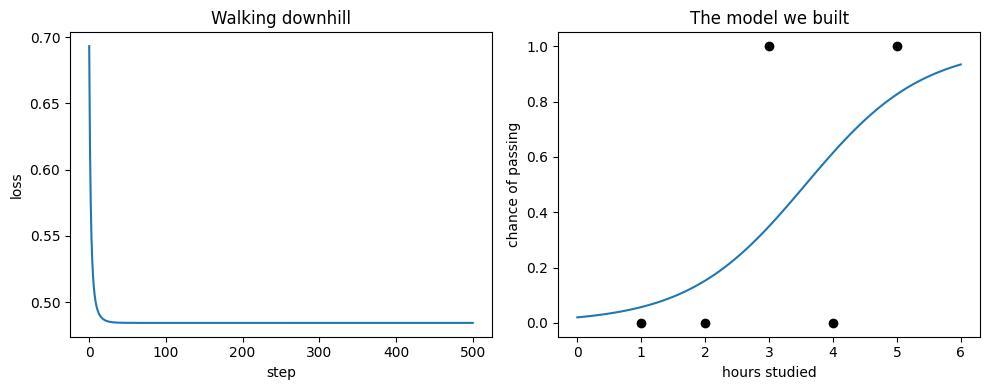

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

# 5 students: hours studied and whether they passed (1 = passed)
hours  = np.array([1, 2, 3, 4, 5.0])
passed = np.array([0, 0, 1, 0, 1.0])
x = hours - hours.mean()      # subtract the average so the walk is smoother
y = passed

def sigmoid(z):
    return 1 / (1 + np.exp(-z))      # turns any number into a percentage between 0 and 1

def loss(w, b):
    p = sigmoid(w * x + b)           # the model's percentage for each student
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))   # how wrong it is on average (smaller is better)

def feel_slope(w, b, h=1e-6):
    # nudge w a tiny bit each way and see how much the loss changes
    dw = (loss(w + h, b) - loss(w - h, b)) / (2 * h)
    db = (loss(w, b + h) - loss(w, b - h)) / (2 * h)
    return dw, db

w, b = 0.0, 0.0       # start knowing nothing: every student gets 50%
step_size = 0.5
history = [loss(w, b)]
print("start:  w =", w, " b =", b, " loss =", round(loss(w, b), 4))

for step in range(1, 501):
    dw, db = feel_slope(w, b)
    w = w - step_size * dw           # take a small step downhill
    b = b - step_size * db
    history.append(loss(w, b))
    if step in (1, 2, 3, 5, 10, 20, 50, 100, 200, 500):
        print(f"step {step:3d}: w = {w:.4f}  b = {b:.4f}  loss = {history[-1]:.4f}")

# compare with the ready-made library (almost no penalty, so it should match)
lib = LogisticRegression(C=1e6).fit(x.reshape(-1, 1), y)
print("\nours   : w =", round(w, 4), " b =", round(b, 4))
print("library: w =", round(lib.coef_[0][0], 4), " b =", round(lib.intercept_[0], 4))

print("\nhours  passed  model's percentage")
for h_, y_, p_ in zip(hours, passed, sigmoid(w * x + b)):
    print(f"{h_:4.0f}   {y_:4.0f}     {p_*100:5.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(history); ax[0].set_xlabel("step"); ax[0].set_ylabel("loss"); ax[0].set_title("Walking downhill")
grid = np.linspace(0, 6, 100)
ax[1].plot(grid, sigmoid(w * (grid - hours.mean()) + b))
ax[1].scatter(hours, passed, color="black")
ax[1].set_xlabel("hours studied"); ax[1].set_ylabel("chance of passing"); ax[1].set_title("The model we built")
plt.tight_layout(); plt.show()